# Polynomial Regression — IMT2023592
Predict `y` from the inputs with polynomial regression on two datasets (var1: 6 inputs, var2: 3 inputs). Each section below does one step.

## 0. Setup and load data
Import libraries and read the train/test CSVs (in Colab, upload the 4 CSVs when prompted).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, itertools, os, warnings
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
warnings.filterwarnings("ignore"); np.random.seed(42)
os.makedirs("figures", exist_ok=True)
ROLLNO = "IMT2023592"

try:
    from google.colab import files; files.upload()      # select the 4 CSVs
except ImportError:
    pass

train1, test1 = pd.read_csv(f"{ROLLNO}_train_var1.csv"), pd.read_csv(f"{ROLLNO}_test_var1.csv")
train2, test2 = pd.read_csv(f"{ROLLNO}_train_var2.csv"), pd.read_csv(f"{ROLLNO}_test_var2.csv")
X1, y1 = train1.drop(columns="y").values, train1["y"].values
X2, y2 = train2.drop(columns="y").values, train2["y"].values
print("var1:", train1.shape, test1.shape, "| var2:", train2.shape, test2.shape)

var1: (1000, 7) (1000, 6) | var2: (1000, 4) (1000, 3)


## 1. Look at the data
All inputs lie in [-1, 1] and many values sit exactly on ±1 (the data was clipped). The covariance heatmap shows how inputs relate to each other and to `y`.

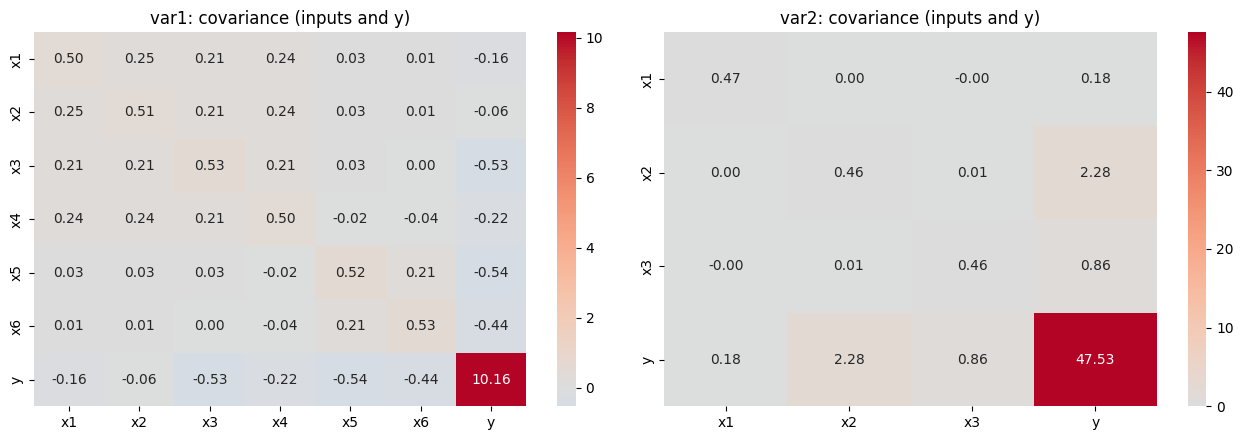

var1: share of input values exactly on +-1 -> train 32%, test 50%
var2: share of input values exactly on +-1 -> train 25%, test 23%


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, df, t in zip(ax, (train1, train2), ("var1", "var2")):
    sns.heatmap(df.cov(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=a); a.set_title(f"{t}: covariance (inputs and y)")
plt.tight_layout(); plt.savefig("figures/covariance.png", dpi=150); plt.show()

for name, tr, te in (("var1", train1, test1), ("var2", train2, test2)):
    f_tr = (tr.drop(columns="y").abs() == 1).values.mean(); f_te = (te.abs() == 1).values.mean()
    print(f"{name}: share of input values exactly on +-1 -> train {f_tr:.0%}, test {f_te:.0%}")

## 2. Build polynomial features by hand
`poly_design_matrix` creates every term $x_1^{a_1}\cdots x_n^{a_n}$ with $a_1+\dots+a_n\le d$ (the assignment's definition of degree). Checked against sklearn.

In [3]:
def poly_design_matrix(X, degree):
    """All monomials of total degree 1..degree (no bias column)."""
    cols, names = [], []
    for d in range(1, degree + 1):
        for combo in itertools.combinations_with_replacement(range(X.shape[1]), d):
            cols.append(np.prod(X[:, combo], axis=1)); names.append("*".join(f"x{i+1}" for i in combo))
    return np.column_stack(cols), names

Xd, _ = poly_design_matrix(X1[:50], 4)
print("matches sklearn:", np.allclose(Xd, PolynomialFeatures(4, include_bias=False).fit_transform(X1[:50])))
for n, d in ((6, 5), (3, 12)):
    print(f"{n} inputs, degree {d} -> {PolynomialFeatures(d).fit(np.zeros((1, n))).n_output_features_ - 1} terms")

matches sklearn: True
6 inputs, degree 5 -> 461 terms
3 inputs, degree 12 -> 454 terms


## 3. Closed-form ridge regression
The normal equation $\theta=(X^TX+\lambda I)^{-1}X^Ty$ written by hand and compared with sklearn's `Ridge`. The $\lambda I$ term keeps the matrix invertible when there are hundreds of terms.

In [4]:
def closed_form_ridge(X, y, lam):
    Xb = np.column_stack([np.ones(len(X)), X]); I = np.eye(Xb.shape[1]); I[0, 0] = 0   # do not penalise the bias
    return np.linalg.pinv(Xb.T @ Xb + lam * I) @ Xb.T @ y

P, _ = poly_design_matrix(X1[:200], 3); th = closed_form_ridge(P, y1[:200], 1.0)
mine = np.column_stack([np.ones(200), P]) @ th
print("max |mine - sklearn Ridge| =", np.abs(mine - Ridge(alpha=1.0).fit(P, y1[:200]).predict(P)).max())

max |mine - sklearn Ridge| = 4.4297898682543746e-14


## 4. Choose the degree (cross-validation U-curve)
For each degree we fit Ridge with 5-fold CV (best `alpha` per degree). Training error keeps falling, but CV error turns back up once the model overfits.

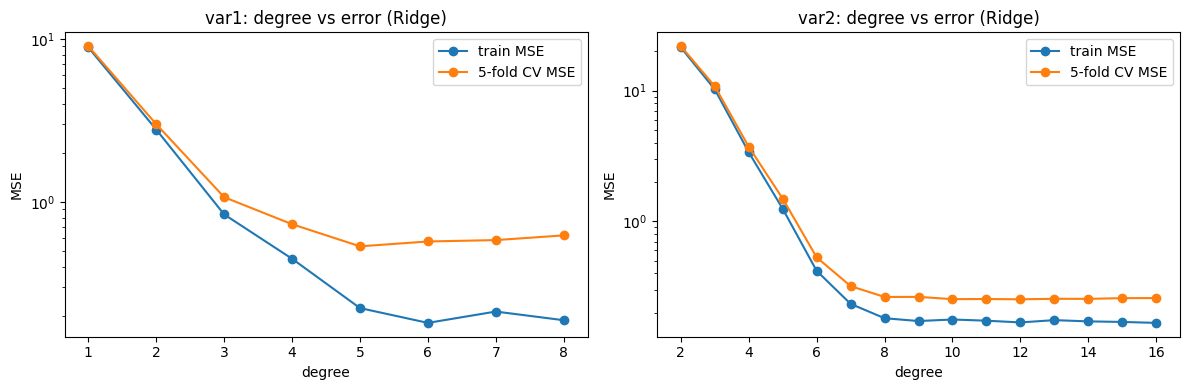

,degree,best_alpha,cv_mse,train_mse
0,1,30,9.039,8.880
1,2,3,3.002,2.782
2,3,1,1.071,0.840
3,4,3,0.731,0.449
4,5,3,0.535,0.224
5,6,3,0.573,0.181
6,7,10,0.584,0.213
7,8,10,0.624,0.188


,degree,best_alpha,cv_mse,train_mse
0,2,1.00,21.833,21.355
1,3,0.30,10.782,10.199
2,4,0.01,3.714,3.374
3,5,0.01,1.493,1.248
4,6,0.01,0.531,0.419
5,7,0.01,0.320,0.234
6,8,0.01,0.264,0.182
7,9,0.01,0.265,0.173
8,10,0.10,0.255,0.178
9,11,0.10,0.255,0.174


In [5]:
kf = KFold(5, shuffle=True, random_state=42)
def cv_mse(model, X, y): return -cross_val_score(model, X, y, cv=kf, scoring="neg_mean_squared_error").mean()

def degree_sweep(X, y, degrees, alphas):
    rows = []
    for d in degrees:
        P = PolynomialFeatures(d, include_bias=False).fit_transform(X)
        errs = {a: cv_mse(Ridge(alpha=a), P, y) for a in alphas}
        a = min(errs, key=errs.get)
        tr = mean_squared_error(y, Ridge(alpha=a).fit(P, y).predict(P))
        rows.append(dict(degree=d, best_alpha=a, cv_mse=errs[a], train_mse=tr))
    return pd.DataFrame(rows)

sw1 = degree_sweep(X1, y1, range(1, 9), [0.01, 0.1, 1, 3, 10, 30])
sw2 = degree_sweep(X2, y2, range(2, 17), [0.001, 0.01, 0.1, 0.3, 1])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, sw, t in zip(ax, (sw1, sw2), ("var1", "var2")):
    a.plot(sw.degree, sw.train_mse, "o-", label="train MSE"); a.plot(sw.degree, sw.cv_mse, "o-", label="5-fold CV MSE")
    a.set_yscale("log"); a.set_xlabel("degree"); a.set_ylabel("MSE"); a.set_title(f"{t}: degree vs error (Ridge)"); a.legend()
plt.tight_layout(); plt.savefig("figures/degree_curve.png", dpi=150); plt.show()
display(sw1.round(3)); display(sw2.round(3))

**Reading the result:** var1 is clearly best at degree 5 (error falls until 5, rises after). var2 drops until about degree 8–10 and then stays flat at about 0.25, so any degree from 10 to 16 is equally good; we use 12.

## 5. Improvement: Lasso keeps only the useful terms (var1)
A degree-5 polynomial in 6 inputs has 461 terms, but the true function uses only some of them. Lasso sets unneeded coefficients to exactly zero, which reduces overfitting. Terms are scaled first and `alpha` is picked by repeated CV. As a second check, we train on rows with at most 2 clipped inputs and validate on rows with at least 3, because var1's test set has far more clipped inputs than its train set.

In [6]:
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=7)
P1 = PolynomialFeatures(5, include_bias=False).fit_transform(X1)
n_clip = (np.abs(X1) == 1).sum(1); easy, hard = n_clip <= 2, n_clip >= 3

def lasso(a): return make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000))
def compare(name, model):
    cv = -cross_val_score(model, P1, y1, cv=rkf, scoring="neg_mean_squared_error").mean()
    tl = mean_squared_error(y1[hard], model.fit(P1[easy], y1[easy]).predict(P1[hard]))
    return dict(model=name, cv_mse=cv, test_like_mse=tl)

cmp1 = pd.DataFrame([compare("Ridge deg5 alpha=3", Ridge(alpha=3))] +
                    [compare(f"Lasso deg5 alpha={a}", lasso(a)) for a in [0.005, 0.01, 0.02, 0.03]])
display(cmp1.round(3))

,model,cv_mse,test_like_mse
0,Ridge deg5 alpha=3,0.511,0.964
1,Lasso deg5 alpha=0.005,0.371,0.743
2,Lasso deg5 alpha=0.01,0.354,0.560
3,Lasso deg5 alpha=0.02,0.379,0.518
4,Lasso deg5 alpha=0.03,0.425,0.601


## 6. Final models, predictions and metrics
Fit on all training rows, write the submission files, and report CV metrics (the honest estimate of test performance; training metrics are optimistic).

In [7]:
final = {1: dict(model=lasso(0.01), degree=5, desc="Lasso (alpha=0.01), degree 5"),
         2: dict(model=Ridge(alpha=0.1), degree=12, desc="Ridge (alpha=0.1), degree 12")}
data = {1: (X1, y1, test1.values), 2: (X2, y2, test2.values)}
summary = []
for v, cfg in final.items():
    X, y, Xt = data[v]; pf = PolynomialFeatures(cfg["degree"], include_bias=False)
    P, Pt = pf.fit_transform(X), pf.transform(Xt)
    cv = cross_validate(cfg["model"], P, y, cv=rkf, scoring=("r2", "neg_mean_squared_error"))
    cfg["model"].fit(P, y); tr_pred = cfg["model"].predict(P); cfg["pf"] = pf
    pd.DataFrame({"y": cfg["model"].predict(Pt)}).to_csv(f"{ROLLNO}_pred_var{v}.csv", index=False)
    summary.append(dict(var=v, model=cfg["desc"], terms=P.shape[1], train_MSE=mean_squared_error(y, tr_pred), train_R2=r2_score(y, tr_pred),
                        cv_MSE=-cv["test_neg_mean_squared_error"].mean(), cv_R2=cv["test_r2"].mean()))
summary = pd.DataFrame(summary); display(summary.round(4))
for v in (1, 2):
    d = pd.read_csv(f"{ROLLNO}_pred_var{v}.csv"); print(f"var{v}: {d.shape}, columns={list(d.columns)}, NaNs={int(d.isna().sum().sum())}")

,var,model,terms,train_MSE,train_R2,cv_MSE,cv_R2
0,1,"Lasso (alpha=0.01), degree 5",461,0.264,0.9740,0.3543,0.9647
1,2,"Ridge (alpha=0.1), degree 12",454,0.169,0.9964,0.2512,0.9946


var1: (1000, 1), columns=['y'], NaNs=0
var2: (1000, 1), columns=['y'], NaNs=0


## 6b. Download the prediction files
In Colab this downloads both prediction CSVs to your computer; outside Colab the files are already saved in the current folder.

In [ ]:
try:
    from google.colab import files
    for v in (1, 2):
        files.download(f"{ROLLNO}_pred_var{v}.csv")
except ImportError:
    print("Not running in Colab - files are saved in the current folder:", [f"{ROLLNO}_pred_var{v}.csv" for v in (1, 2)])

## 7. Which terms matter, and how good is the fit
The largest Lasso coefficients (on scaled terms) show which input products drive `y` in var1. Predicted-vs-actual plots (out-of-fold predictions) should hug the diagonal.

var1: 114 of 461 terms kept; top 12 by size:


,coef
x1 x5,-1.346
x2^3 x3,-1.014
x3 x6,-0.805
x3^3 x6^2,-0.800
x6^2,0.785
x2 x4 x6,-0.656
x2 x6,0.595
x1 x3^2 x6^2,-0.529
x2^2 x4^2 x5,-0.507
x3^2 x4^2,-0.456


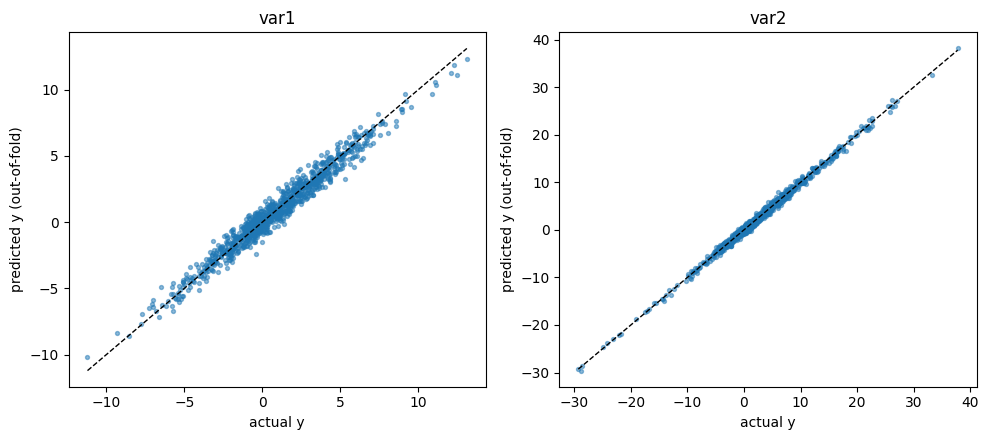

In [8]:
lm = final[1]["model"]; names = final[1]["pf"].get_feature_names_out([f"x{i+1}" for i in range(6)])
coef = pd.Series(lm[-1].coef_, index=names); nz = coef[coef != 0]
print(f"var1: {len(nz)} of {len(coef)} terms kept; top 12 by size:")
display(nz.reindex(nz.abs().sort_values(ascending=False).index).head(12).round(3).to_frame("coef"))

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, v in zip(ax, (1, 2)):
    X, y, _ = data[v]; pred = cross_val_predict(final[v]["model"], final[v]["pf"].transform(X), y, cv=kf)
    a.scatter(y, pred, s=8, alpha=0.5); lim = [y.min(), y.max()]; a.plot(lim, lim, "k--", lw=1)
    a.set_xlabel("actual y"); a.set_ylabel("predicted y (out-of-fold)"); a.set_title(f"var{v}")
plt.tight_layout(); plt.savefig("figures/pred_vs_actual.png", dpi=150); plt.show()